In [1]:
!nvidia-smi
!pip install -q ultralytics gradio

Wed Nov 25 13:10:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from ultralytics.data.utils import check_det_dataset

voc_info = check_det_dataset("VOC.yaml")
voc_root = str(voc_info["path"])
print("Veri seti dizini:", voc_root)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

WARNING ⚠️ Dataset 'VOC.yaml' images not found, missing path '/content/datasets/VOC/images/test2007'
Unzipping /content/datasets/VOC/images/VOCtest_06-Nov-2007.zip to /content/datasets/VOC/images/VOCdevkit...: 100% ━━━━━━━━━━━━ 10357/10357 817.7files/s 12.7s
Unzipping /content/datasets/VOC/images/VOCtrainval_06-Nov-2007.zip to /content/datasets/VOC/images/VOCdevkit...: 100% ━━━━━━━━━━━━ 10945/10945 931.3files/s 11.8s
Unzipping /content/datasets/VOC/images/VOCtrainval_11-May-2012.zip to /content/datasets/VOC/images/VOCdevkit...: 100% ━━━━━━━━━━━━ 40189/40189 1.5Kfiles/s 26.1s
train2012: 100% ━━━━━━━━━━━━ 5717/5717 2.6Kit/s 2.2s
val2012: 100% ━━━━━━━━━━━━ 5823/5823 2.8Kit/s 2.1s
train2007: 100% ━━━━━

In [3]:
import yaml

voc_names = {
    0: 'aeroplane', 1: 'bicycle', 2: 'bird', 3: 'boat', 4: 'bottle',
    5: 'bus', 6: 'car', 7: 'cat', 8: 'chair', 9: 'cow',
    10: 'diningtable', 11: 'dog', 12: 'horse', 13: 'motorbike', 14: 'person',
    15: 'pottedplant', 16: 'sheep', 17: 'sofa', 18: 'train', 19: 'tvmonitor'
}

voc_split_config = {
    'path': voc_root,
    'train': ['images/train2012', 'images/train2007'],
    'val': 'images/val2007',
    'test': 'images/test2007',
    'names': voc_names
}

with open('voc_split.yaml', 'w') as f:
    yaml.dump(voc_split_config, f, sort_keys=False)

print("voc_split.yaml başarıyla oluşturuldu.")

voc_split.yaml başarıyla oluşturuldu.


In [4]:
import time
from ultralytics import YOLO

model = YOLO('yolov8s.pt')

start_train = time.time()

results = model.train(
    data='voc_split.yaml',
    epochs=25,
    imgsz=640,
    batch=16,
    optimizer='AdamW',
    lr0=0.001,
    weight_decay=0.0005,
    patience=7,
    project='voc_yolo_project',
    name='yolov8s_voc',
    device=0
)

train_duration_min = (time.time() - start_train) / 60
print(f"\n>>> Toplam Eğitim Süresi: {train_duration_min:.2f} dakika")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=voc_split.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_voc, nbs=64, nms=None, opset=None, optimize=False, optimizer=Ada

Bulunan dosyalar: ['runs/detect/voc_yolo_project/yolov8s_voc/weights/best.pt']
Kullanılan model yolu: runs/detect/voc_yolo_project/yolov8s_voc/weights/best.pt
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,133,324 parameters, 0 gradients, 28.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 15.8±5.1 MB/s, size: 114.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/datasets/VOC/labels/test2007... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 478.9it/s 10.3s
val: New cache created: /content/datasets/VOC/labels/test2007.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 310/310 4.9it/s 1:04
                   all       4952      12032      0.797      0.745      0.813      0.599
             ae

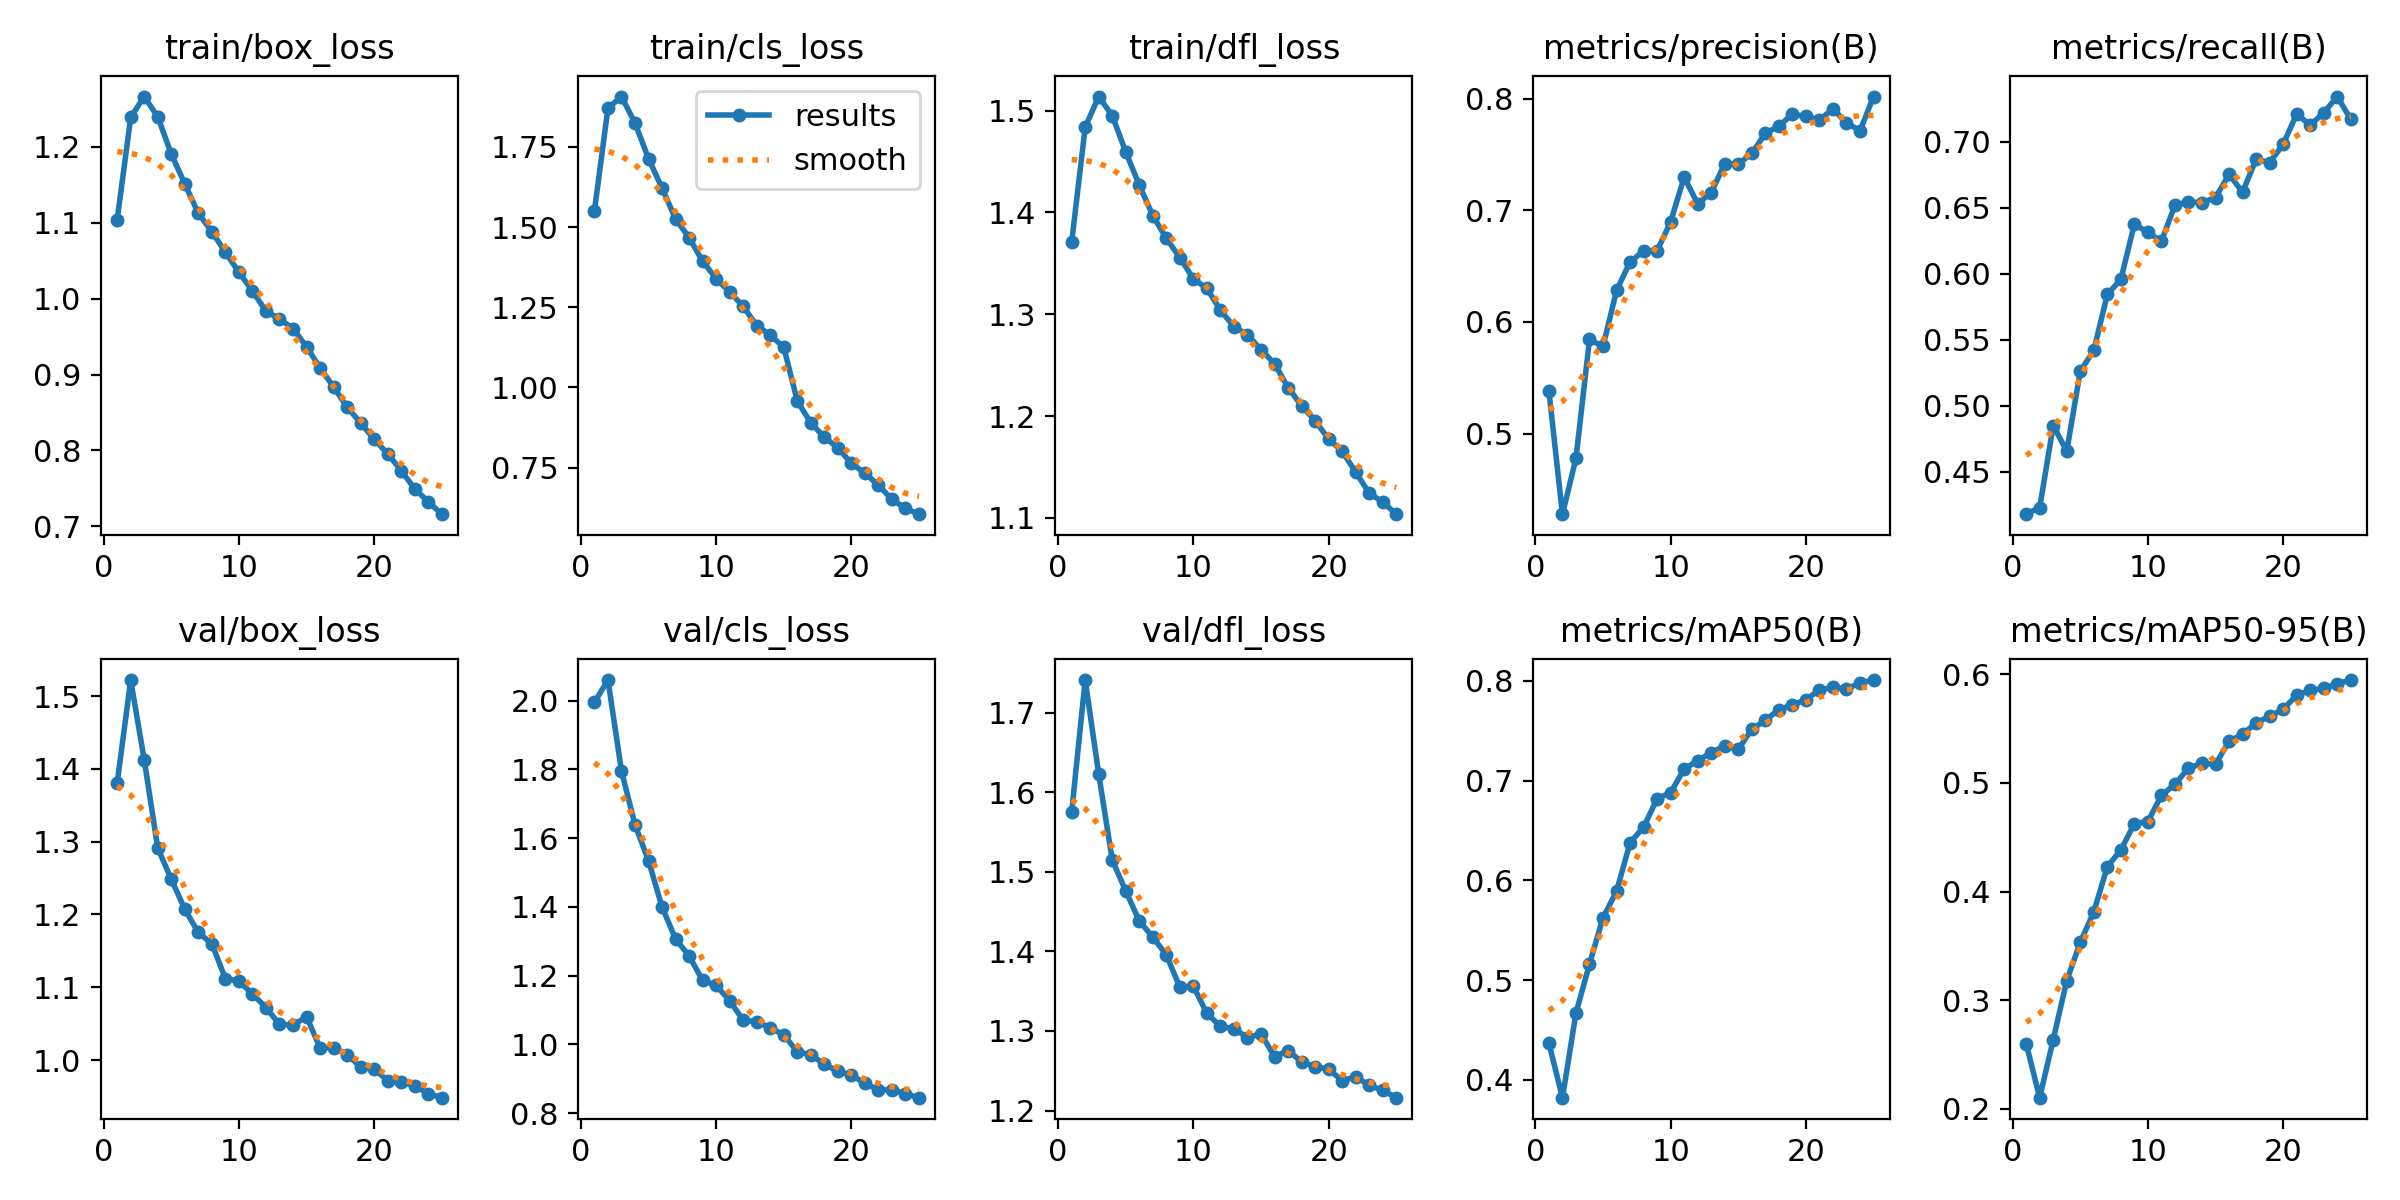

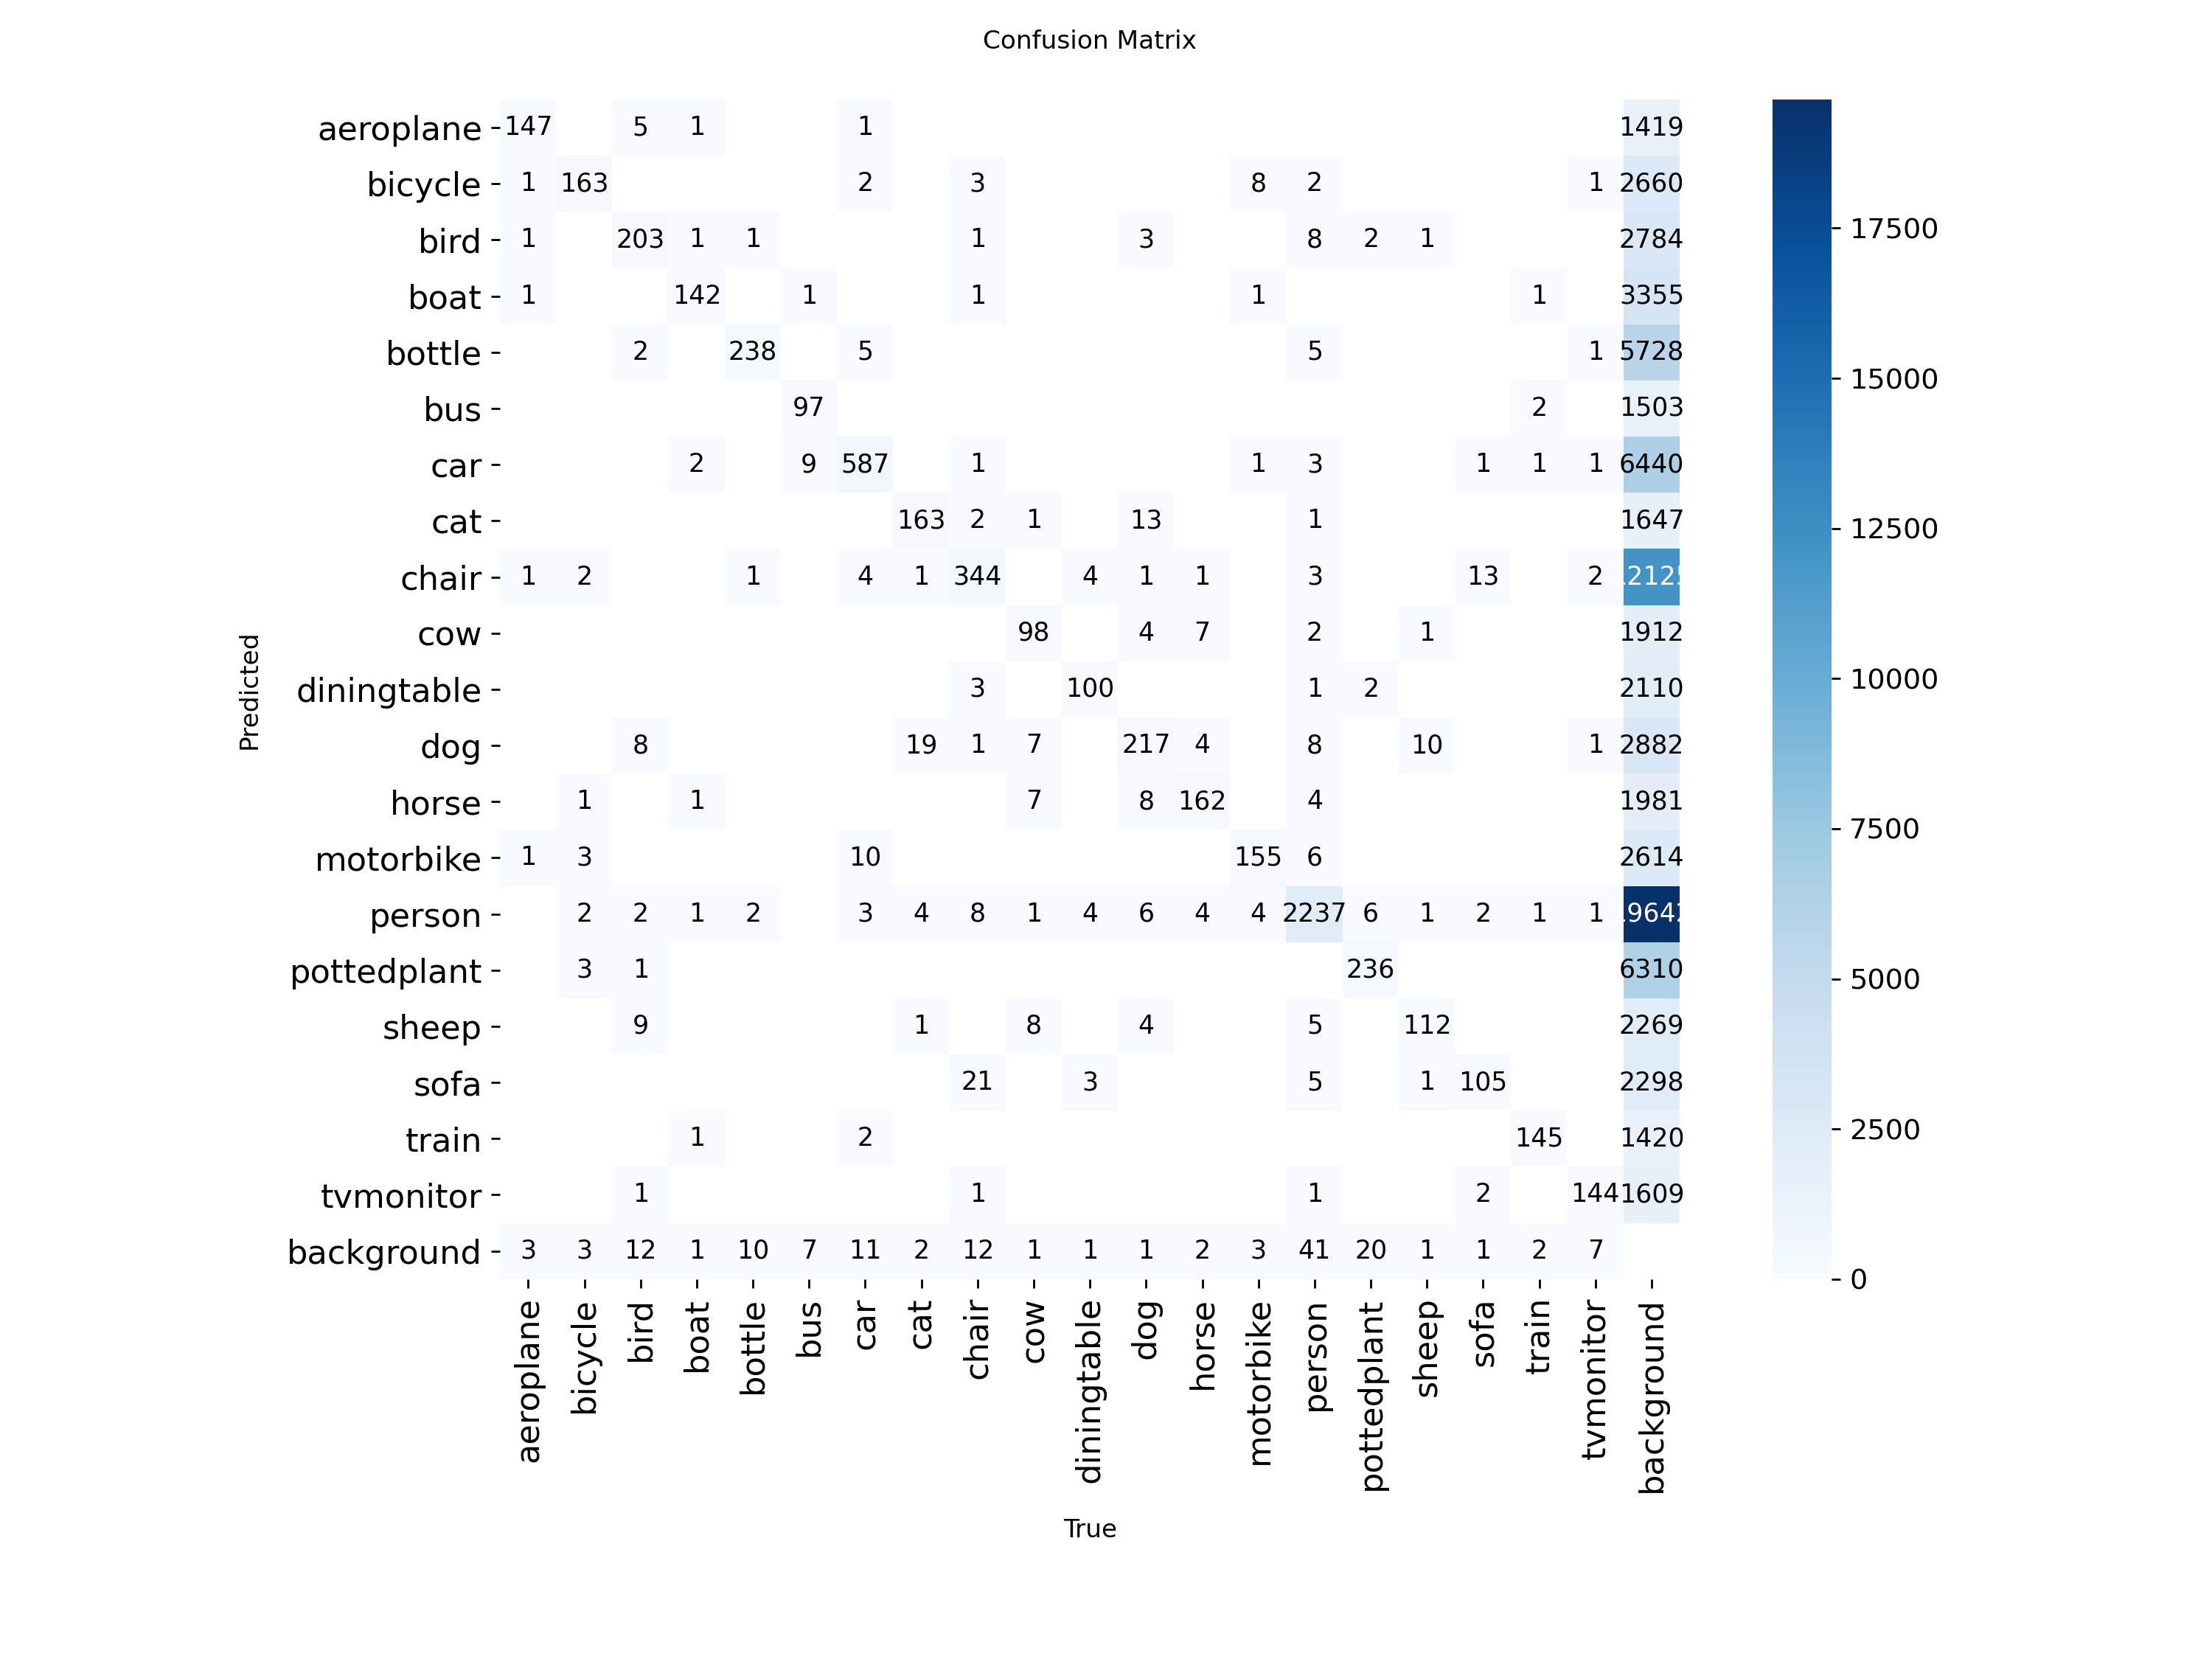

In [7]:
import glob, os
from pathlib import Path
from IPython.display import Image, display
from ultralytics import YOLO

# best.pt dosyasını tüm alt klasörlerde ara (en son kaydedileni seç)
found = sorted(glob.glob("**/best.pt", recursive=True), key=os.path.getmtime)
print("Bulunan dosyalar:", found)

best_path = found[-1]
run_dir = Path(best_path).parent.parent
print("Kullanılan model yolu:", best_path)

best_model = YOLO(best_path)
metrics = best_model.val(data='voc_split.yaml', split='test', imgsz=640)

print("\n=== TEST KÜMESİ SONUÇLARI ===")
print(f"mAP@0.5:      {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {metrics.box.map:.4f}")
print(f"Precision:    {metrics.box.mp:.4f}")
print(f"Recall:       {metrics.box.mr:.4f}")

speed = metrics.speed
print(f"\n=== TAHMİN SÜRESİ (ms / görsel) ===")
print(f"Preprocess:  {speed['preprocess']:.2f} ms")
print(f"Inference:   {speed['inference']:.2f} ms")
print(f"Postprocess: {speed['postprocess']:.2f} ms")

display(Image(filename=str(run_dir / 'results.png'), width=800))
display(Image(filename=str(run_dir / 'confusion_matrix.png'), width=700))

In [8]:
from google.colab import files

files.download(best_path)
files.download(str(run_dir / 'results.png'))
files.download(str(run_dir / 'confusion_matrix.png'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import time
import cv2
import gradio as gr
from ultralytics import YOLO

model_app = YOLO(best_path)

def detect_objects(image, conf_threshold):
    if image is None:
        return None, "Lütfen bir görüntü yükleyin."

    start_t = time.perf_counter()
    image_bgr = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    results = model_app.predict(source=image_bgr, conf=conf_threshold, imgsz=640, verbose=False)
    elapsed_ms = (time.perf_counter() - start_t) * 1000

    res = results[0]
    annotated_bgr = res.plot()
    annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

    counts = {}
    for box in res.boxes:
        cls_name = model_app.names[int(box.cls[0])]
        counts[cls_name] = counts.get(cls_name, 0) + 1

    if counts:
        summary_lines = [f"- **{k}**: {v} adet" for k, v in counts.items()]
        summary = f"### Tespit Edilen Nesneler (Süre: {elapsed_ms:.1f} ms)\n" + "\n".join(summary_lines)
    else:
        summary = f"Eşik değeri ({conf_threshold}) üzerinde nesne tespit edilemedi. (Süre: {elapsed_ms:.1f} ms)"

    return annotated_rgb, summary

demo = gr.Interface(
    fn=detect_objects,
    inputs=[
        gr.Image(type="numpy", label="Fotoğraf Yükle"),
        gr.Slider(minimum=0.1, maximum=0.9, value=0.35, step=0.05, label="Güven Eşiği (Confidence)")
    ],
    outputs=[
        gr.Image(type="numpy", label="Model Çıktısı (Bounding Box)"),
        gr.Markdown(label="Tahmin Özeti")
    ],
    title="YOLOv8s – Pascal VOC Nesne Tespiti",
    description="Bir fotoğraf yükleyerek Pascal VOC sınıfları (20 sınıf) üzerinde nesne tespiti yapabilirsiniz."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://fec19527ac9c4a03db.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
